# Binary Logistic Regression

## Is this message spam?

A spam filter assigns each message one of two labels: legitimate ($y=0$) or spam ($y=1$). Spam is the positive class because it is the event being detected. These labels describe message categories, not the number of words or links.

Two measured features summarize each synthetic message. $x_1$ counts promotional phrases, such as “free prize” or “special offer,” and $x_2$ counts links. A real feature extractor would count those patterns in message text; this example directly simulates the counts and labels. The two synthetic feature groups have a deliberate gap so that a fitted linear score can separate them completely.

The model creates a combined feature, the linear score $z$, from both inputs:

$$
z=b+w_1x_1+w_2x_2.
$$

The intercept $b$ is the score when both counts are zero. The weights $w_1$ and $w_2$ determine each count's contribution. Fitting learns all three values. The score $z$ can be negative or positive; it is not yet a probability.

The sigmoid converts this score into the model's estimated spam probability:

$$
p=P(y=1\mid\mathbf{x})=\sigma(z)=\frac{1}{1+e^{-z}}.
$$

Here, $e$ is the base of the natural exponential. A larger $z$ gives a larger $p$; $z=0$ gives $p=0.5$. Legitimate messages have estimated probability $1-p$.

<img src="https://raw.githubusercontent.com/sonamu-jun/introduction-to-ai-convergence/main/07-1_Classification/assets/02_sigmoid_and_threshold.png" alt="Two message counts combine into a learned score z. A sigmoid converts z into spam probability, and a threshold selects spam or legitimate." width="512" style="max-width:100%;height:auto;">

A threshold $\tau$ turns the probability into a class:

$$
\hat y=\begin{cases}1\;\text{(Spam)},&p\ge\tau,\\0\;\text{(Legitimate)},&p<\tau.\end{cases}
$$

At $\tau=0.5$, the decision boundary is $b+w_1x_1+w_2x_2=0$, a straight line in the two-feature plane. Logistic regression is a classifier even though its name contains “regression.”


## Learning the weights

Binary cross-entropy penalizes low probability for the observed class. For one labeled message, the loss is

$$
\ell(y,p)=-\big[y\log p+(1-y)\log(1-p)\big].
$$

The label $y$ selects the relevant term: spam contributes $-\log p$, and a legitimate message contributes $-\log(1-p)$. The logarithm is natural. A confidently wrong prediction therefore receives a large penalty. The training loss $L$ is the mean of these losses across training messages.

Gradient descent changes each fitted parameter in the direction that reduces $L$:

$$
\theta\leftarrow\theta-\eta\,\frac{\partial L}{\partial\theta}.
$$

Here, $\theta$ is an intercept or weight, $\partial L/\partial\theta$ measures how the loss changes with that parameter, and $\eta$ is the learning rate. The code standardizes inputs using training statistics for stable updates and converts the learned coefficients back to raw counts for the displayed $z$ equation.

At iteration zero, the initial weights give overlapping scores for legitimate and spam messages. Both colors overlap along the sigmoid curve. The iteration control selects actual gradient descent updates; `Fit model` selects update 600. As the weights change, legitimate messages move along the curve toward the lower left and spam messages toward the upper right. At the default threshold of 0.5, the two classes are completely separated after fitting. The saved preview shows this fitted state.

Each training point is plotted at $(z,\sigma(z))$: its horizontal position is the current score and its height is the predicted spam probability. Its color is the observed class. Messages with identical scores overlap. The sigmoid shape, axis ranges, original counts, and labels stay fixed; learning changes the scores and moves the points along the curve.

The orange marker shows the new message on the same curve. Changing either count updates its score, sigmoid probability, and prediction together. The horizontal dashed line marks the probability threshold; the vertical dotted line and background colors show its corresponding score boundary. Changing the threshold changes decisions without changing scores, probabilities, or training loss. Displayed coefficients are rounded; calculations use full precision. Validation accuracy uses separate messages that never update the coefficients.


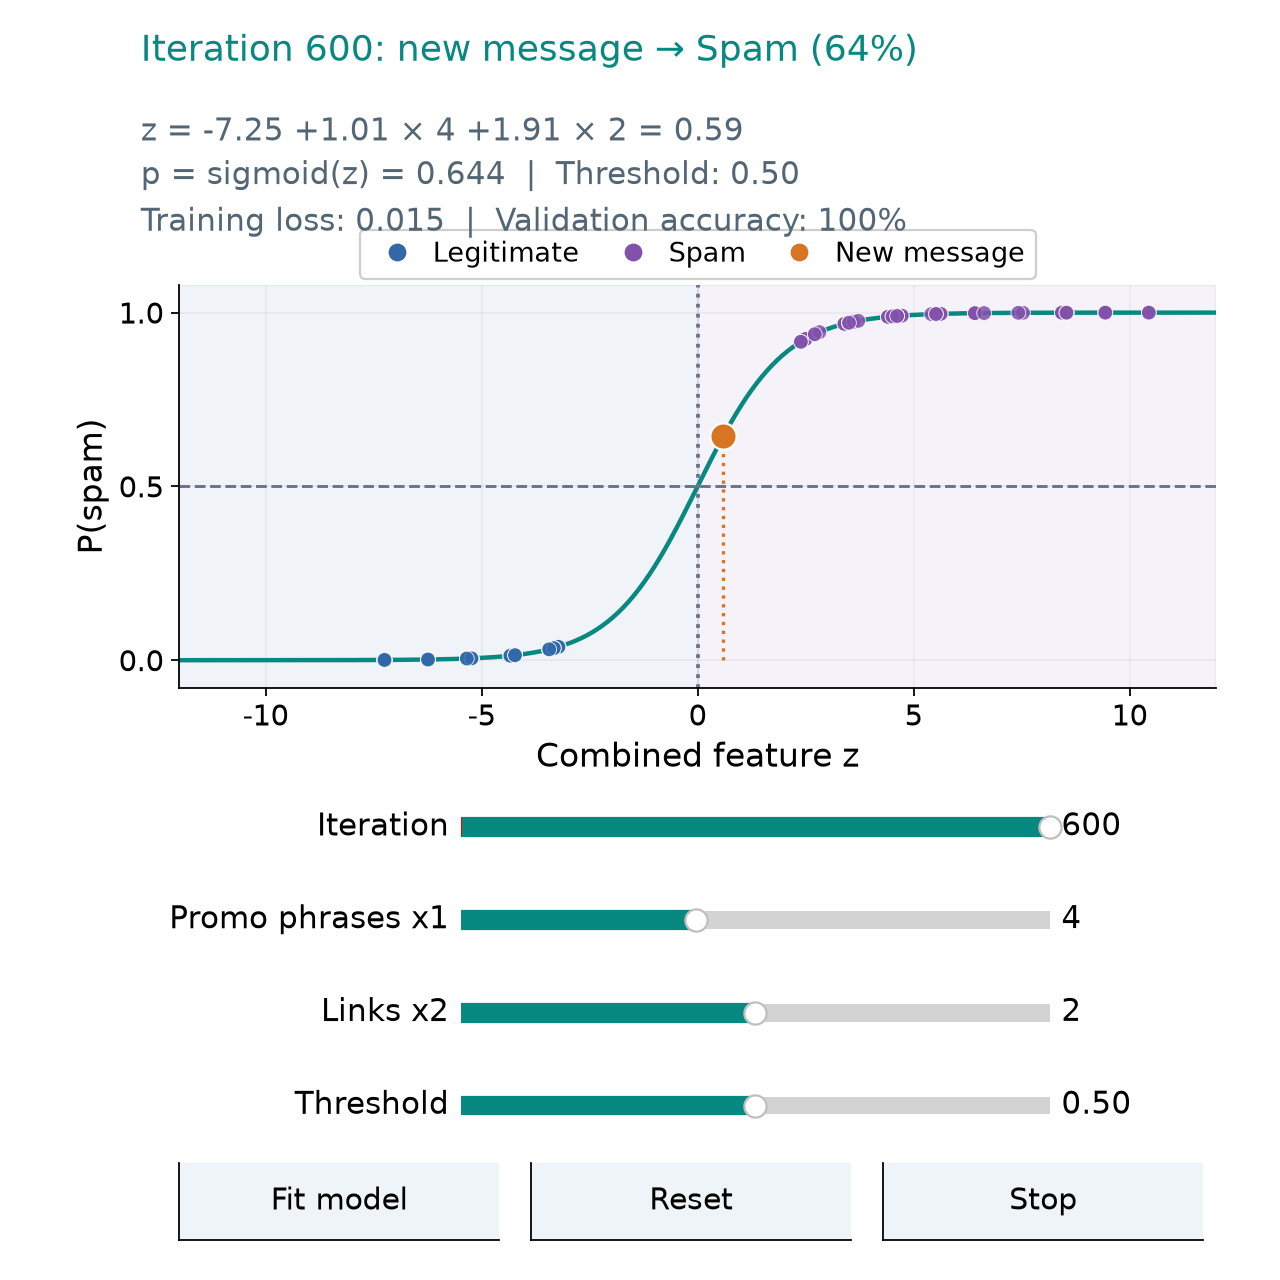

In [1]:
import os
import sys
import io
import numpy as np
import matplotlib

CLASSIFICATION_STATIC = os.environ.get("CLASSIFICATION_STATIC") == "1"
CLASSIFICATION_BROWSER = sys.platform == "emscripten"
if not CLASSIFICATION_STATIC and not CLASSIFICATION_BROWSER:
    from IPython import get_ipython
    shell = get_ipython()
    if shell is not None and getattr(shell, "kernel", None) is not None:
        shell.run_line_magic("matplotlib", "widget")

import matplotlib.pyplot as plt
from matplotlib.widgets import Slider, Button
from matplotlib.colors import ListedColormap
from IPython.display import Image, display
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

plt.rcParams.update({
    "font.size": 15, "axes.labelsize": 15,
    "xtick.labelsize": 13, "ytick.labelsize": 13, "legend.fontsize": 12,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": .16, "lines.linewidth": 2.5,
    "axes.unicode_minus": False, "figure.facecolor": "white",
})
BLUE, TEAL, ORANGE, PURPLE = "#3268a8", "#078880", "#d87522", "#8251ac"


def sigmoid(score):
    score = np.clip(np.asarray(score, dtype=float), -500, 500)
    return 1 / (1 + np.exp(-score))


def softmax(scores):
    scores = np.asarray(scores, dtype=float)
    weights = np.exp(scores - scores.max(axis=-1, keepdims=True))
    return weights / weights.sum(axis=-1, keepdims=True)


def binary_loss(labels, scores):
    # The logaddexp form avoids taking log(0) at extreme scores.
    return float(np.mean(np.logaddexp(0, scores) - labels * scores))


def classification_metrics(observed, predicted):
    observed, predicted = np.asarray(observed), np.asarray(predicted)
    tp = int(np.sum((observed == 1) & (predicted == 1)))
    tn = int(np.sum((observed == 0) & (predicted == 0)))
    fp = int(np.sum((observed == 0) & (predicted == 1)))
    fn = int(np.sum((observed == 1) & (predicted == 0)))
    return {"TP": tp, "TN": tn, "FP": fp, "FN": fn,
            "accuracy": (tp + tn) / len(observed),
            "precision": tp / (tp + fp) if tp + fp else np.nan,
            "recall": tp / (tp + fn) if tp + fn else np.nan,
            "F1": 2 * tp / (2 * tp + fp + fn) if 2 * tp + fp + fn else np.nan}


def percent(value):
    return "undefined" if not np.isfinite(value) else f"{value:.0%}"


# A rerun releases the previous figure and its input callbacks first.
for _previous_view in globals().get("_classification_views", {}).values():
    _previous_view.close()
_classification_views = {}


class ClassificationExplorer:
    """One figure keeps the selected model, predictions and scores together."""

    def __init__(self, name, render, sliders, actions=()):
        self.render = render
        self.slider_specs = sliders
        self.controls, self.buttons, self.state = {}, {}, {}
        self.stopped = False
        self.defaults = {key: initial for key, label, low, high, initial, step, fmt in sliders}
        with plt.ioff():
            height = min(8.0, 6.8 + .58 * len(sliders))
            self.figure = plt.figure(figsize=(8, height), dpi=64)
        self.status = self.figure.text(.11, 1 - .38 / height, "", fontsize=16, color=TEAL)
        self.detail = self.figure.text(.11, 1 - .66 / height, "", va="top", fontsize=14, color="#536675", linespacing=1.5)
        bottom = (1.38 + .58 * len(sliders)) / height
        top = 1 - 1.78 / height
        self.ax = self.figure.add_axes([.14, bottom, .81, top - bottom])
        for i, (key, label, low, high, initial, step, fmt) in enumerate(sliders):
            y = (.98 + .58 * (len(sliders) - i - 1)) / height
            slider = Slider(self.figure.add_axes([.36, y, .46, .22 / height]),
                            label, low, high, valinit=initial, valstep=step,
                            valfmt=fmt, color=TEAL)
            slider.label.set_fontsize(14)
            slider.valtext.set_fontsize(14)
            slider.on_changed(self.update)
            self.controls[key] = slider
        commands = list(actions) + [("Reset", lambda view: view.reset()),
                                    ("Stop", lambda view: view.stop())]
        self.commands = commands
        width = min(.25, .83 / len(commands) - .025)
        for i, (label, callback) in enumerate(commands):
            button = Button(self.figure.add_axes([.14 + i * (width + .025), .25 / height, width, .48 / height]),
                            label, color="#eef4f7", hovercolor="#d7e9e6")
            button.label.set_fontsize(13.5)
            button.on_clicked(lambda event, cb=callback: cb(self) if not self.stopped else None)
            self.buttons[label] = button
        self.figure.canvas.mpl_connect("close_event", lambda event: self.stop())
        _classification_views[name] = self
        self.update()

    def update(self, _=None):
        if self.stopped:
            return
        self.ax.clear()
        self.state = self.render(self, **{key: slider.val for key, slider in self.controls.items()})
        self.figure.canvas.draw_idle()
        self.refresh_local()

    def set_values(self, **values):
        if self.stopped:
            return
        for key, value in values.items():
            slider = self.controls[key]
            events, drawing = slider.eventson, slider.drawon
            slider.eventson = slider.drawon = False
            slider.set_val(value)
            slider.eventson, slider.drawon = events, drawing
        self.update()

    def reset(self):
        self.set_values(**self.defaults)

    def refresh_local(self):
        if not hasattr(self, "local_image"):
            return
        from matplotlib.transforms import Bbox
        width, height = self.figure.get_size_inches()
        # Crop only the embedded Matplotlib controls; native widgets follow the chart.
        lower = max(0, self.ax.get_position().y0 * height - .78)
        buffer = io.BytesIO()
        self.figure.savefig(buffer, format="png", dpi=64, facecolor="white",
                            bbox_inches=Bbox.from_extents(0, lower, width, height))
        self.local_image.value = buffer.getvalue()
        self.syncing_local = True
        for key, control in self.local_controls.items():
            control.value = self.controls[key].val
        self.syncing_local = False

    def start_local(self):
        from ipywidgets import Image as WidgetImage, FloatSlider, IntSlider
        from ipywidgets import Button as WidgetButton, HBox, VBox, Layout
        self.syncing_local = False
        self.local_image = WidgetImage(format="png", layout=Layout(
            width="100%", max_width="512px", height="auto"))
        self.local_controls, self.local_buttons = {}, {}
        for key, label, low, high, initial, step, fmt in self.slider_specs:
            slider_type = IntSlider if fmt == "%0.0f" and step == 1 else FloatSlider
            control = slider_type(value=initial, min=low, max=high, step=step,
                                  description=label, readout_format=fmt.replace("%0", ""),
                                  continuous_update=True,
                                  style={"description_width": "120px"},
                                  layout=Layout(width="100%", max_width="512px"))
            def changed(change, key=key):
                if not self.syncing_local and not self.stopped:
                    self.controls[key].set_val(change["new"])
            control.observe(changed, names="value")
            self.local_controls[key] = control
        for label, callback in self.commands:
            button = WidgetButton(description=label, layout=Layout(
                flex="1 1 0", min_width="120px", height="34px", margin="2px"))
            button.on_click(lambda _, cb=callback: cb(self) if not self.stopped else None)
            self.local_buttons[label] = button
        row = HBox(list(self.local_buttons.values()), layout=Layout(width="100%", flex_flow="row wrap"))
        self.local_row = row
        self.local_output = VBox([self.local_image, *self.local_controls.values(), row],
                                layout=Layout(width="100%", max_width="512px"))
        self.refresh_local()
        display(self.local_output)

    def start(self):
        if CLASSIFICATION_STATIC:
            buffer = io.BytesIO()
            self.figure.savefig(buffer, format="png", dpi=160, facecolor="white")
            display(Image(data=buffer.getvalue(), width=512,
                          alt=self.status.get_text() + ". " + self.detail.get_text()))
            plt.close(self.figure)
        elif CLASSIFICATION_BROWSER:
            # JSPCV sends mouse events after this cell has returned.
            plt.show(block=False)
        elif hasattr(self.figure.canvas, "toolbar_visible"):
            # The ipympl figure supplies a responsive chart with native widget controls.
            self.start_local()
        else:
            plt.show(block=False)

    def stop(self):
        if self.stopped:
            return
        self.stopped = True
        for control in list(self.controls.values()) + list(self.buttons.values()):
            control.set_active(False)
        for control in [*getattr(self, "local_controls", {}).values(),
                        *getattr(self, "local_buttons", {}).values()]:
            control.disabled = True
        if hasattr(self, "local_buttons"):
            self.local_buttons["Stop"].description = "Stopped"
        self.buttons["Stop"].label.set_text("Stopped")
        self.figure.canvas.draw_idle()

    def close(self):
        self.stop()
        for control in list(self.controls.values()) + list(self.buttons.values()):
            control.disconnect_events()
        plt.close(self.figure)
        if hasattr(self, "local_output"):
            self.local_output.close()
            self.local_image.close()
            self.local_row.close()
            for control in [*self.local_controls.values(), *self.local_buttons.values()]:
                control.close()



def make_messages(seed, count=240, spam_fraction=.35):
    """Synthetic labels and counts; no real messages or URLs are collected."""
    rng = np.random.default_rng(seed)
    labels = np.zeros(count, dtype=int)
    labels[:round(count * spam_fraction)] = 1
    rng.shuffle(labels)
    phrases = rng.binomial(10, np.where(labels == 1, .53, .13))
    links = rng.binomial(4, np.where(labels == 1, .57, .13))
    return np.column_stack([phrases, links]), labels


def make_fruit(seed):
    """Synthetic fruit measurements: hue in degrees and length / width."""
    rng = np.random.default_rng(seed)
    labels = np.repeat(np.arange(3), 60)
    centers = np.array([[8, 1.15], [30, 1.05], [53, 2.8]])
    spreads = np.array([[8, .18], [7, .16], [7, .5]])
    values = centers[labels] + rng.normal(size=(len(labels), 2)) * spreads[labels]
    return np.clip(values, [0, .7], [70, 4.2]), labels

# This fitting example deliberately separates the two synthetic feature groups.
# The evaluation example explores mistakes with independently controlled counts.
rng = np.random.default_rng(70)
feature_grid = np.array([(phrases, links) for phrases in range(11) for links in range(5)])
construction_score = feature_grid[:, 0] + 2 * feature_grid[:, 1]
labels = np.zeros(240, dtype=int)
labels[:84] = 1
rng.shuffle(labels)
messages = np.empty((len(labels), 2), dtype=int)
for label, pool in [(0, feature_grid[construction_score <= 4]),
                    (1, feature_grid[construction_score >= 10])]:
    selected = labels == label
    messages[selected] = pool[rng.integers(len(pool), size=selected.sum())]
train_id, validation_id = train_test_split(np.arange(len(labels)), test_size=.3,
                                         stratify=labels, random_state=70)
feature_mean = messages[train_id].mean(axis=0)
feature_scale = messages[train_id].std(axis=0)


def message_features(values):
    values = np.atleast_2d(values)
    return np.column_stack([np.ones(len(values)), (values - feature_mean) / feature_scale])


def raw_coefficients(beta):
    # Undo training-only standardization so the displayed equation uses raw counts.
    weights = beta[1:] / feature_scale
    return np.r_[beta[0] - feature_mean @ weights, weights]


train_features = message_features(messages[train_id])
# Opposing initial weights produce overlapping scores before learning.
coefficients = np.array([0., 1., -1.])
coefficient_history = [coefficients.copy()]
for iteration in range(600):
    probability = sigmoid(train_features @ coefficients)
    gradient = train_features.T @ (probability - labels[train_id]) / len(train_id)
    coefficients -= .15 * gradient
    coefficient_history.append(coefficients.copy())
coefficient_history = np.asarray(coefficient_history)
# Cover every allowed query at every update without rescaling the horizontal axis.
all_query_scores = message_features(feature_grid) @ coefficient_history.T
score_limit = float(np.ceil(np.abs(all_query_scores).max()) + 1)
score_grid = np.linspace(-score_limit, score_limit, 601)


def render_binary(view, iteration, phrases, links, threshold):
    beta = coefficient_history[int(iteration)]
    raw = raw_coefficients(beta)
    query = np.array([[phrases, links]])
    score = float((message_features(query) @ beta)[0])
    probability = float(sigmoid(score))
    train_scores = train_features @ beta
    train_probability = sigmoid(train_scores)
    validation_probability = sigmoid(message_features(messages[validation_id]) @ beta)
    predicted = (validation_probability >= threshold).astype(int)
    result = classification_metrics(labels[validation_id], predicted)
    loss = binary_loss(labels[train_id], train_scores)
    ax = view.ax
    boundary = float(np.log(threshold / (1 - threshold)))
    ax.axvspan(-score_limit, boundary, color=BLUE, alpha=.07)
    ax.axvspan(boundary, score_limit, color=PURPLE, alpha=.07)
    ax.plot(score_grid, sigmoid(score_grid), color=TEAL, linewidth=2, zorder=2)
    colors = np.where(labels[train_id] == 0, BLUE, PURPLE)
    # Both coordinates come from this update; color alone represents the label.
    ax.scatter(train_scores, train_probability, s=44, c=colors,
               alpha=.85, edgecolors="white", linewidths=.4, zorder=3)
    ax.axvline(boundary, color="#64748b", linestyle=":", linewidth=1.7)
    ax.axhline(threshold, color="#64748b", linestyle="--", linewidth=1.3)
    ax.plot([score, score], [0, probability], ":", color=ORANGE, linewidth=1.5)
    ax.scatter([score], [probability], s=140, color=ORANGE, edgecolor="white", zorder=5)
    from matplotlib.lines import Line2D
    handles = [Line2D([], [], linestyle="", marker="o", color=color,
                      markersize=7, label=label)
               for color, label in [(BLUE, "Legitimate"), (PURPLE, "Spam"),
                                    (ORANGE, "New message")]]
    ax.legend(handles=handles, loc="lower center", bbox_to_anchor=(.5, 1.015),
              ncol=3, fontsize=12, framealpha=.95, borderaxespad=0,
              handletextpad=.35, columnspacing=1.)
    ax.set(xlim=(-score_limit, score_limit), ylim=(-.08, 1.08),
           xlabel="Combined feature z", ylabel="P(spam)", yticks=[0, .5, 1])
    label = "Spam" if probability >= threshold else "Legitimate"
    view.status.set_text(f"Iteration {int(iteration)}: new message → {label} ({probability:.0%})")
    view.detail.set_text(
        f"z = {raw[0]:.2f} {raw[1]:+.2f} × {phrases:.0f} {raw[2]:+.2f} × {links:.0f} = {score:.2f}\n"
        f"p = sigmoid(z) = {probability:.3f}  |  Threshold: {threshold:.2f}\n"
        f"Training loss: {loss:.3f}  |  Validation accuracy: {result['accuracy']:.0%}")
    return {"probability": probability, "label": label, "score": score, "query": query,
            "boundary": boundary,
            "train_probability": train_probability, "score_limit": score_limit,
            "coefficients": beta.copy(), "raw_coefficients": raw,
            "train_scores": train_scores, "validation_probability": validation_probability,
            "prediction": predicted, "metrics": result, "loss": loss}


binary_demo = ClassificationExplorer("binary", render_binary, [
    ("iteration", "Iteration", 0, 600, 0, 1, "%0.0f"),
    ("phrases", "Promo phrases x1", 0, 10, 4, 1, "%0.0f"),
    ("links", "Links x2", 0, 4, 2, 1, "%0.0f"),
    ("threshold", "Threshold", .05, .95, .5, .05, "%0.2f"),
], actions=[("Fit model", lambda view: view.set_values(iteration=600))])
if CLASSIFICATION_STATIC:
    # The saved preview shows the fitted separation; live execution starts at zero.
    binary_demo.set_values(iteration=600)
binary_demo.start()


## Counts do not capture meaning

This deliberately separable dataset illustrates how fitting creates a useful score. Real messages need not separate: legitimate offers can contain promotional phrases and links, while spam can avoid them. Two counts cannot represent sender identity, context, or message meaning.

Logistic regression uses a linear boundary in these features. A straight boundary cannot describe every possible class pattern. Lowering the threshold catches more spam and may hide more legitimate messages. A separate test set is needed after choosing settings with validation data.
